# 02 · Preparação, modelagem e interpretação

> ⚠️ **Dados 100% simulados.** A base foi gerada por `src/generate_data.py` (seed=42) apenas para fins de portfólio.

**Pergunta:** dá para prever, no momento do cadastro, quais leads vão comprar?

Este notebook tem três partes:
1. **Preparação dos dados:** tratamento, features e divisão sem vazamento (código em `src/features.py`).
2. **Modelagem:** regressão logística como baseline e XGBoost como modelo principal (código em `src/train.py`).
3. **Interpretação:** o que o modelo aprendeu, explicado com SHAP.

## Parte 1 · Preparação dos dados

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

from src.features import (
    EXCLUDED_COLUMNS, NUMERIC_FEATURES, BINARY_FEATURES, CATEGORICAL_FEATURES,
    add_features, build_preprocessor, load_leads, split_data,
)
from src.plots import COLORS, conversion_by, plot_rate_bars, save_figure, set_style

set_style()
pd.set_option("display.float_format", "{:,.3f}".format)
df = load_leads()

### 1.1 Divisão treino / validação / teste (70/15/15)

A divisão é feita **antes de qualquer tratamento** e é **estratificada pelo alvo**. Com só 4% de compradores, uma divisão
aleatória simples poderia deixar o teste com uma taxa de conversão diferente, distorcendo as métricas.

- **Treino (70%):** ajusta o pré-processamento e os modelos, e é onde roda a validação cruzada.
- **Validação (15%):** compara modelos e escolhe o limiar de decisão.
- **Teste (15%):** fica guardado até o fim e é usado uma única vez, para a estimativa final e a análise de impacto.

In [2]:
X_train, X_val, X_test, y_train, y_val, y_test = split_data(df)

pd.DataFrame({
    "leads": [len(y_train), len(y_val), len(y_test)],
    "conversoes": [y_train.sum(), y_val.sum(), y_test.sum()],
    "taxa_conversao": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["treino", "validacao", "teste"])

,leads,conversoes,taxa_conversao
treino,35000,1411,0.040
validacao,7500,303,0.040
teste,7500,302,0.040


**Conclusão:** os três conjuntos têm a mesma taxa de conversão (4,03–4,04%), como esperado com a estratificação.
São cerca de 300 compradores na validação e no teste, o suficiente para comparar modelos com estabilidade razoável.

### 1.2 Tratamento de ausentes e outliers

| Problema | Tratamento | Justificativa |
|---|---|---|
| ~2% de ausentes em `idade` e `tempo_no_site_seg` | Mediana **do treino** | A mediana é robusta à cauda longa do tempo no site, e calcular só no treino evita vazamento. |
| ~2% de ausentes em `dispositivo` e `uf` | Categoria `"desconhecido"` | Falha de rastreamento pode ter padrão próprio, e a categoria extra preserva essa informação. |
| Sessões acima de 1 hora (0,5%) | Capping em 3.600 s | Abas esquecidas e bots. Limitar o valor em vez de remover a linha mantém o lead, e o teto é uma regra de negócio fixa, que não depende dos dados. |
| UFs com menos de 1% dos leads | Agrupadas em "infrequente" | Evita colunas com pouquíssimos exemplos, que só adicionam ruído. |

### 1.3 Features novas

| Feature | Como é calculada | Por que (achado da EDA) |
|---|---|---|
| `faixa_etaria` | 18–24, 25–34, 35–44, 45–60 | A conversão cresce com a idade. |
| `periodo_do_dia` | madrugada (0–5h), manhã (6–11h), tarde (12–17h), noite (18–23h) | O horário muda a intenção de compra. |
| `dia_da_semana` | segunda a domingo | Captura sazonalidade semanal sem decorar datas. |
| `engajamento` | log(1 + páginas) + log(1 + minutos no site) | Combina duas medidas de interesse na mesma escala. |
| `mobile_noite` | celular **e** cadastro entre 22h e 6h | Foi o segmento com a pior conversão na EDA. A regressão logística não cria essa interação sozinha. |

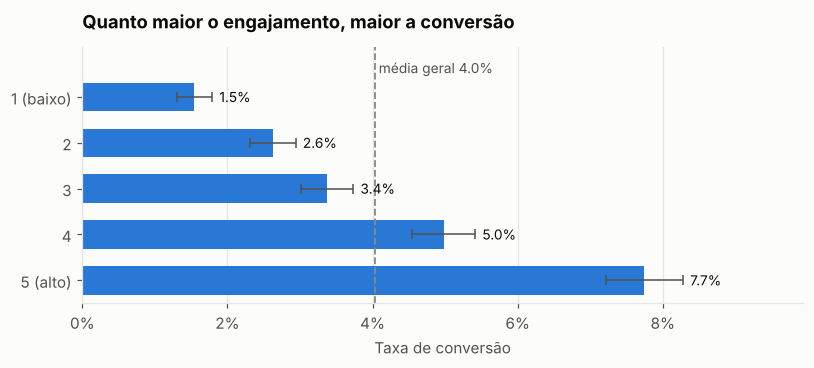

,leads,conversoes,taxa,ic95
quintil_engajamento,,,,
1 (baixo),9840,152,0.015,0.002
2,9799,257,0.026,0.003
3,9805,331,0.034,0.004
4,9778,487,0.050,0.004
5 (alto),9797,759,0.077,0.005


In [3]:
com_features = add_features(df)
com_features["quintil_engajamento"] = pd.qcut(
    com_features["engajamento"], 5, labels=["1 (baixo)", "2", "3", "4", "5 (alto)"]
)
por_engajamento = conversion_by(com_features, "quintil_engajamento")
fig = plot_rate_bars(
    por_engajamento, "Quanto maior o engajamento, maior a conversão",
    com_features["converteu"].mean(), sort=False, show_ci=True,
)
save_figure(fig, "10_conversao_por_engajamento")
plt.show()
por_engajamento

**Conclusão:** a nova feature `engajamento` separa bem os leads: os 20% mais engajados convertem **5 vezes mais** (7,8%) que os 20% menos
engajados (1,5%), com crescimento consistente entre os quintis. É um sinal forte, construído só com dados disponíveis no cadastro.

### 1.4 A coluna `custo_aquisicao_lead` deve entrar no modelo?

Há argumentos para os dois lados:

- **A favor:** o custo pode indicar um lead "disputado" no leilão de mídia, que talvez tenha mais intenção.
- **Contra:** (1) ele é quase todo explicado pelo canal, que já está no modelo; (2) na prática, o custo por lead é **rateado depois**,
  quando a fatura da campanha fecha, então não estaria disponível no momento de pontuar um lead novo, e usá-lo seria um tipo de vazamento temporal;
  (3) o custo é o que queremos **otimizar** na análise de impacto, e usá-lo como entrada misturaria causa e consequência.

Vamos verificar o argumento (1) com os dados:

In [4]:
from sklearn.linear_model import LinearRegression

canais = pd.get_dummies(df["canal"])
r2_canal = LinearRegression().fit(canais, df["custo_aquisicao_lead"]).score(canais, df["custo_aquisicao_lead"])
print(f"R² do custo explicado apenas pelo canal: {r2_canal:.1%}")

df.groupby("canal")["custo_aquisicao_lead"].describe()[["mean", "std", "min", "max"]]

R² do custo explicado apenas pelo canal: 65.7%


,mean,std,min,max
canal,,,,
email,2.663,0.954,0.670,8.360
google_ads,19.207,6.957,5.050,70.450
meta_ads,12.702,4.554,2.950,54.290
organico,1.064,0.381,0.230,3.820
tiktok_ads,9.542,3.445,2.260,29.060


**Conclusão:** só o canal já explica cerca de **2/3 da variação do custo** (R² de 66%), e o resto é variação aleatória em torno do custo médio do canal.
**Decisão: o custo fica fora do modelo.** Ele traria pouca informação nova, não estaria disponível em tempo real e será usado, separadamente,
para medir o impacto em CPA na Etapa 6. Também ficam de fora `lead_id` (identificador), `data_cadastro` e `horario_cadastro`
(substituídas por `dia_da_semana` e `periodo_do_dia`).

### 1.5 Pipeline sem vazamento de dados

Todo o pré-processamento fica em um único `Pipeline` do scikit-learn:

```
Pipeline
├── features: add_features (capping + features novas, linha a linha)
└── columns: ColumnTransformer
    ├── num: SimpleImputer(mediana) → StandardScaler
    ├── bin: passthrough
    └── cat: SimpleImputer("desconhecido") → OneHotEncoder
```

O pipeline é ajustado (`fit`) **só no treino**. Na validação cruzada, ele é reajustado dentro de cada fold, então nem o fold
de validação "vaza" as medianas, médias ou categorias para o treino.

In [5]:
preprocessador = build_preprocessor()
X_train_proc = preprocessador.fit_transform(X_train)
X_test_proc = preprocessador.transform(X_test)
nomes = preprocessador.named_steps["columns"].get_feature_names_out()

mediana_treino = preprocessador.named_steps["columns"].named_transformers_["num"].named_steps["imputer"].statistics_
print(f"Treino: {X_train_proc.shape} | Teste: {X_test_proc.shape}")
print(f"Ausentes depois do pipeline: {np.isnan(X_train_proc).sum() + np.isnan(X_test_proc).sum()}")
print("Medianas aprendidas SÓ no treino:", {c: round(float(v), 2) for c, v in zip(NUMERIC_FEATURES, mediana_treino)})
print(f"Colunas excluídas: {EXCLUDED_COLUMNS}")
print(f"{len(nomes)} colunas finais, por exemplo: {list(nomes[:10])}")

Treino: (35000, 61) | Teste: (7500, 61)
Ausentes depois do pipeline: 0
Medianas aprendidas SÓ no treino: {'idade': 32.0, 'paginas_vistas': 4.0, 'tempo_no_site_seg': 104.0, 'engajamento': 2.62}
Colunas excluídas: ['lead_id', 'data_cadastro', 'horario_cadastro', 'custo_aquisicao_lead']
61 colunas finais, por exemplo: ['idade', 'paginas_vistas', 'tempo_no_site_seg', 'engajamento', 'visitou_pagina_preco', 'abriu_email', 'mobile_noite', 'canal_email', 'canal_google_ads', 'canal_meta_ads']


**Conclusão:** o pipeline gera 61 colunas sem nenhum valor ausente, e as estatísticas de imputação vêm só do treino.
O mesmo objeto será acoplado aos modelos na Parte 2, então quem usar o modelo em produção passa os dados brutos e recebe a probabilidade:
o tratamento vai junto.